# Självstudieövningar – Vecka 7

De här övningarna är till för att du ska repetera och befästa det vi har gått igenom under veckan samt introducera några nya begrepp på ett tryggt sätt.

Det innebär att vissa av uppgifterna kan du behöva söka efter information själv hur du löser. Här kan du använda Google eller AI om du vill men dokumentationerna är din bästa vän när du lär dig.
- Python: https://docs.python.org/3.13/
- Matplotlib: https://matplotlib.org/stable/
- Pandas: https://pandas.pydata.org/
- NumPy: https://numpy.org/

Läs först igenom vad som ska göras i respektive uppgift och fyll sedan i kodblocket nedanför, eller gör uppgiften i en separat fil.

**Detta lämnas inte in för rättning.** Arbeta i din egen takt, testa dig fram, använd dokumentationen när du kör fast och ta med eventuella frågor till nästa lektionstillfälle.

## (Kör först) Skapa veckans dataset

In [2]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(123)

n = 800
cities = np.array(["Göteborg", "Malmö", "Stockholm", "Uppsala"])
genders = np.array(["F", "M"])
groups = np.array(["A", "B"])

city = rng.choice(cities, size=n, p=[0.28, 0.22, 0.40, 0.10])
gender = rng.choice(genders, size=n)
age = rng.integers(18, 65, size=n)
group = rng.choice(groups, size=n)

base = rng.normal(60, 12, size=n)
city_shift = {"Göteborg": 2, "Malmö": -1, "Stockholm": 1, "Uppsala": 0}
gender_shift = {"F": 1.5, "M": 0}
score = base + np.vectorize(city_shift.get)(city) + np.vectorize(gender_shift.get)(gender)
score = score + np.where(group == "B", 2.0, 0.0)
score = np.clip(score, 10, 100)

p_buy = 1 / (1 + np.exp(-(score - 55) / 10))
purchase = rng.binomial(1, p_buy)
revenue = np.where(purchase == 1, rng.lognormal(mean=3.2, sigma=0.5, size=n), 0.0)

df = pd.DataFrame({
    "city": city,
    "gender": gender,
    "age": age,
    "group": group,
    "score": np.round(score, 1),
    "purchase": purchase,
    "revenue": np.round(revenue, 2)
})

mask = rng.random(size=df.shape) < 0.01
for (row, column), is_missing in np.ndenumerate(mask):
    if is_missing:
        df.iat[row, column] = np.nan

df.to_csv("customer_activity.csv", index=False)
print("Skapade customer_activity.csv med", len(df), "rader.")

Skapade customer_activity.csv med 800 rader.


### Om datasetet (`customer_activity.csv`)

Det här är samma syntetiska dataset från den fiktiva digitala tjänsten som användes under vecka 5 och 6. Grupp B har en liten positiv effekt på `score`, och sannolikheten för ett köp ökar med högre `score`.

| Kolumn | Typ | Beskrivning |
|---|---|---|
| `city` | kategori | Kundens stad |
| `gender` | kategori | Kön (F/M) |
| `age` | heltal | Ålder |
| `group` | kategori | Grupp A eller B |
| `score` | decimaltal | Aktivitet eller engagemang, 10–100 |
| `purchase` | 0/1 | Om kunden genomförde ett köp |
| `revenue` | decimaltal | Intäkt, 0 om inget köp genomfördes |

Eftersom datasetet är syntetiskt ska det användas för att träna analysmetoder. Resultaten beskriver inte verkliga kunder.

### Snabb kontroll

- Läs in `customer_activity.csv` i en DataFrame som heter `df`.
- Kontrollera datatyper och antal saknade värden.
- Kontrollera att `group` bara innehåller A och B samt att `purchase` bara innehåller 0 och 1, bortsett från saknade värden.

In [3]:
df = pd.read_csv("customer_activity.csv")
df.info()
print(df.isna().sum())
print("Group-värden:", set(df["group"].dropna().unique()))
print("Purchase-värden:", set(df["purchase"].dropna().unique()))
assert set(df["group"].dropna().unique()) <= {"A", "B"}
assert set(df["purchase"].dropna().unique()) <= {0, 1}

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   city      795 non-null    str    
 1   gender    788 non-null    str    
 2   age       791 non-null    float64
 3   group     792 non-null    str    
 4   score     792 non-null    float64
 5   purchase  793 non-null    float64
 6   revenue   789 non-null    float64
dtypes: float64(4), str(3)
memory usage: 43.9 KB
city         5
gender      12
age          9
group        8
score        8
purchase     7
revenue     11
dtype: int64
Group-värden: {'A', 'B'}
Purchase-värden: {np.float64(0.0), np.float64(1.0)}


## Block A – A/B-test för andelar

### Uppgift 1 – Test av andelar

Undersök om andelen kunder som genomfört ett köp skiljer sig mellan grupp A och grupp B.

- Ta bort rader där `group` eller `purchase` saknas.
- Kontrollera att `purchase` bara innehåller 0 och 1.
- Beräkna antal observationer, antal köp och köpandel i respektive grupp.
- Formulera en nollhypotes och en tvåsidig mothypotes.
- Kontrollera att det förväntade antalet köp och icke-köp är tillräckligt stort i båda grupperna.
- Genomför ett tvåsidigt z-test för två oberoende andelar.
- Rapportera z-statistika, p-värde och slutsats vid signifikansnivån 5 procent.

**Tips:** `statsmodels.stats.proportion.proportions_ztest()` kan användas.

In [4]:
from statsmodels.stats.proportion import proportions_ztest

test_data = df.dropna(subset=["group", "purchase"]).copy()
assert set(test_data["purchase"].unique()) <= {0, 1}

summary = test_data.groupby("group")["purchase"].agg(["count", "sum", "mean"])
print(summary)

count = np.array([summary.loc["A", "sum"], summary.loc["B", "sum"]])
nobs = np.array([summary.loc["A", "count"], summary.loc["B", "count"]])
pooled = count.sum() / nobs.sum()
expected = {
    "A köp": nobs[0] * pooled,
    "A icke-köp": nobs[0] * (1 - pooled),
    "B köp": nobs[1] * pooled,
    "B icke-köp": nobs[1] * (1 - pooled),
}

print("Förväntade antal under H0:", expected)
print("Normalapproximation rimlig:", min(expected.values()) >= 10)

z_stat, p_value = proportions_ztest(count, nobs, alternative="two-sided")
alpha = 0.05
print("H0: köpandelarna är lika. H1: Köpandelarna skiljer sig.")
print("z-statistika:", z_stat)
print("p-värde:", p_value)
print("Förkasta H0." if p_value < alpha else "Förkasta inte H0")

       count    sum      mean
group                        
A        391  249.0  0.636829
B        394  257.0  0.652284
Förväntade antal under H0: {'A köp': np.float64(252.03312101910828), 'A icke-köp': np.float64(138.96687898089172), 'B köp': np.float64(253.96687898089172), 'B icke-köp': np.float64(140.03312101910828)}
Normalapproximation rimlig: True
H0: köpandelarna är lika. H1: Köpandelarna skiljer sig.
z-statistika: -0.4523560197747076
p-värde: 0.65101252507292
Förkasta inte H0


### Uppgift 2 – Skillnad, konfidensintervall och praktisk betydelse

Fortsätt med köpandelarna från föregående uppgift.

- Beräkna den absoluta skillnaden `p_B - p_A`.
- Uttryck skillnaden i procentenheter.
- Beräkna ett 95-procentigt konfidensintervall för skillnaden mellan andelarna.
- Beräkna relativ förändring för grupp B jämfört med grupp A, om andelen i A är större än 0.
- Skapa en figur som visar den observerade skillnaden och dess konfidensintervall tillsammans med en referenslinje vid 0.

Skriv en kort slutsats där du skiljer mellan statistisk signifikans och praktisk betydelse. Förklara också varför en relativ förändring kan låta stor även när den absoluta skillnaden är liten.

Absolut skillnad B - A: 0.015455619458112135
Skillnad i procentenheter: 1.5455619458112135
95% konfidensintervall: (-0.05150534373166159, 0.08241658264788586)
Relativ föränding: 0.024269667502497372


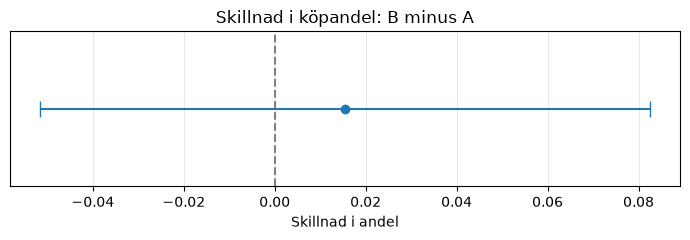

Intervallet innehåller 0, så data get inte tydligt stöd för en skillnad på 5%-nivån.
Praktisk betydelse måste bedömas mot en verksamhetsmässigt relevant minsta effekt.
En relativ förändring dividerar med utgångsnivån och kan därför låta stor när den absoluta skillnaden är liten.


In [5]:
import matplotlib.pyplot as plt
clean = df.dropna(subset=["group", "purchase"])
stats = clean.groupby("group")["purchase"].agg(["count", "mean"])

n_a, n_b = int(stats.loc["A", "count"]), int(stats.loc["B", "count"])
p_a, p_b = float(stats.loc["A", "mean"]), float(stats.loc["B", "mean"])
diff = p_b - p_a
se = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
lower, upper = diff - 1.96 * se, diff + 1.96 * se
relative_change = diff / p_a if p_a > 0 else np.nan

print("Absolut skillnad B - A:", diff)
print("Skillnad i procentenheter:", 100 * diff)
print("95% konfidensintervall:", (float(lower), float(upper)))
print("Relativ föränding:", relative_change)

fig, ax = plt.subplots(figsize=(7, 2.5))
ax.errorbar(diff, 0, xerr=1.96 * se, fmt="o", capsize=6)
ax.axvline(0, color="gray", linestyle="--")
ax.set(title="Skillnad i köpandel: B minus A", xlabel="Skillnad i andel")
ax.grid(True, axis="x", alpha=0.3)
ax.set_yticks([])
plt.tight_layout()
plt.show()

print("Intervallet innehåller 0, så data get inte tydligt stöd för en skillnad på 5%-nivån.")
print("Praktisk betydelse måste bedömas mot en verksamhetsmässigt relevant minsta effekt.")
print("En relativ förändring dividerar med utgångsnivån och kan därför låta stor när den absoluta skillnaden är liten.")

## Block B – Power och stickprovsstorlek

### Uppgift 3 – Planera ett A/B-test

Anta att köpandelen i grupp A normalt är 25 procent. Du vill planera ett tvåsidigt A/B-test med signifikansnivån 5 procent och 80 procents power.

- Beräkna hur många observationer som behövs per grupp för att kunna upptäcka en ökning från 25 till 28 procent.
- Upprepa beräkningen för en ökning från 25 till 27 procent.
- Upprepa beräkningen för en ökning från 25 till 30 procent.
- Samla resultaten i en tabell och skapa en figur som visar sambandet mellan effektstorlek och nödvändig stickprovsstorlek.
- Förklara varför mindre effekter kräver större stickprov.

**Tips:** Använd `proportion_effectsize()` och `NormalIndPower().solve_power()` från `statsmodels`. Avrunda alltid den beräknade stickprovsstorleken uppåt.

,baseline,target,absolute_effect,n_per_group
1,0.25,0.27,0.02,7549
0,0.25,0.28,0.03,3395
2,0.25,0.30,0.05,1250


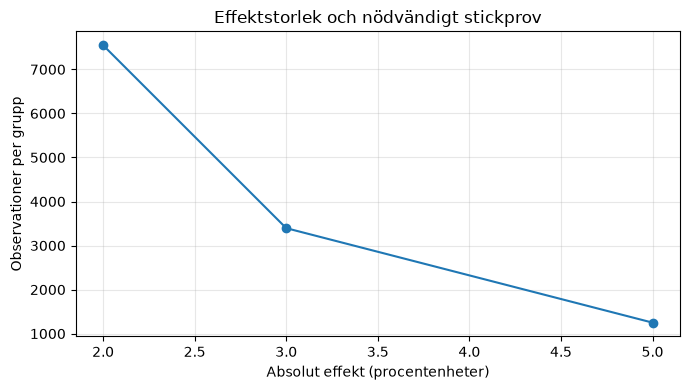

In [7]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

baseline = 0.25
targets = [0.28, 0.27, 0.30]
analysis = NormalIndPower()
rows = []
for target in targets:
    effect_size = abs(proportion_effectsize(target, baseline))
    n_per_group = analysis.solve_power(
        effect_size=effect_size,
        alpha=0.05,
        power=0.80,
        ratio=1,
        alternative="two-sided"
    )
    rows.append({
        "baseline": baseline,
        "target": target,
        "absolute_effect": target - baseline,
        "n_per_group": int(np.ceil(n_per_group))
    })

power_table = pd.DataFrame(rows).sort_values("absolute_effect")
display(power_table)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(100 * power_table["absolute_effect"], power_table["n_per_group"], marker="o")
ax.set(title="Effektstorlek och nödvändigt stickprov", xlabel="Absolut effekt (procentenheter)", ylabel="Observationer per grupp")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Block C – Flerfaldig testning

### Uppgift 4 – Många tester och korrigerade p-värden

Anta att följande p-värden kommer från tio analyser som genomförts samtidigt:

```python
p_values = np.array([0.001, 0.009, 0.018, 0.031, 0.047, 0.072, 0.11, 0.24, 0.51, 0.88])
```

- Avgör vilka tester som är signifikanta utan korrigering vid `alpha = 0.05`.
- Korrigera p-värdena med Bonferronimetoden.
- Korrigera dem även med Benjamini–Hochberg-metoden för FDR.
- Skapa en DataFrame med ursprungligt p-värde, korrigerat p-värde och beslut för båda metoderna.
- Jämför hur många hypoteser som förkastas med respektive metod.
- Förklara varför risken för minst ett falskt positivt resultat ökar när många tester genomförs.

**Tips:** Funktionen `statsmodels.stats.multitest.multipletests()` kan användas med metoderna `"bonferroni"` och `"fdr_bh"`.

In [ ]:
from statsmodels.stats.multitest import multipletests

p_values = np.array([0.001, 0.009, 0.018, 0.031, 0.047, 0.072, 0.11, 0.24, 0.51, 0.88])
alpha = 0.05
uncorrected = p_values < alpha
bonf_reject, bonf_p, _, _ = multipletests(p_values, alpha=alpha, method="bonferroni")
bh_reject, bh_p, _, _ = multipletests(p_values, alpha=alpha, method="fdr_bh")

results = pd.DataFrame({
    "p_original": p_values,
    "significant_uncorrected": uncorrected,
    "p_bonferroni": bonf_p,
    "reject_bonferroni": bonf_reject,
    "p_bh": bh_p,
    "reject_bh": bh_reject,
})
display(results)
print("Förkastade utan korrigering:", int(uncorrected.sum()))
print("Förkastade med Bonferroni:", int(bonf_reject.sum()))
print("Förkastade med Benjamini-Hochberg:", int(bh_reject.sum()))
# Fler tester ger fler chanser att få minst ett litet p-värde av slumpen, även om alla H0 är sanna.